In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import nibabel as nib

import sys
sys.path.append("/home/agustin/phd/synthesis/utils")

import util_freesurfer_segmentation as ufs



from cornucopia.utils.py import meshgrid_ij
from cornucopia import (
    RandomAffineElasticTransform,
    RandomAffineTransform,
    RandomElasticTransform,
    RandomGaussianMixtureTransform,
)

In [2]:
def show_image(img, seg, title=None):
    plt.figure(figsize=(10, 10))
    plt.subplot(1, 2, 1)
    plt.imshow(img.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.title('MRI')
    plt.subplot(1, 2, 2)
    plt.imshow(seg.squeeze(), cmap='tab20', interpolation='nearest')
    plt.axis('off')
    plt.title('Labels')
    plt.show()

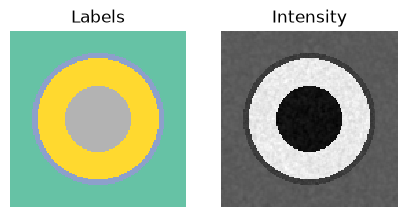

In [3]:
shape = [128, 128]
radius = torch.stack(meshgrid_ij(*[torch.arange(s).float() for s in shape]), -1)
radius -= (torch.as_tensor(shape).float() - 1) / 2
radius = radius.square().sum(-1).sqrt()

lab = torch.zeros_like(radius, dtype=torch.long)
lab[radius < 48] = 1
lab[radius < 44] = 2
lab[radius < 24] = 3
lab = lab[None]  # channel dimension

# we also generate an intenity image from this label map
img = RandomGaussianMixtureTransform()(lab)

plt.figure(figsize=(5, 5))
plt.subplot(1, 2, 1)
plt.imshow(lab.squeeze(), cmap='Set2', interpolation='nearest')
plt.axis('off')
plt.title('Labels')
plt.subplot(1, 2, 2)
plt.imshow(img.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Intensity')
plt.show()

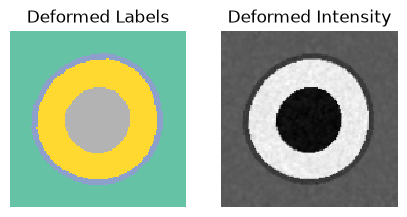

In [22]:
trf = RandomAffineElasticTransform()
wlab, wimg = trf(lab, img)

plt.figure(figsize=(5, 5))
plt.subplot(1, 2, 1)
plt.imshow(wlab.squeeze(), cmap='Set2', interpolation='nearest')
plt.axis('off')
plt.title('Deformed Labels')
plt.subplot(1, 2, 2)
plt.imshow(wimg.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Deformed Intensity')
plt.show()

In [26]:
# shape = [4, 4]

# plt.figure(figsize=(10, 10))
# for i in range(shape[0] * shape[1] // 2):
#     wlab, wimg = trf(lab, img)
#     plt.subplot(*shape, 2*i+1)
#     plt.imshow(wlab.squeeze(), cmap='Set2', interpolation='nearest')
#     plt.axis('off')
#     plt.subplot(*shape, 2*i+2)
#     plt.imshow(wimg.squeeze(), cmap='gray', interpolation='nearest')
#     plt.axis('off')
# plt.suptitle('Affine + Elastic transforms')
# plt.show()

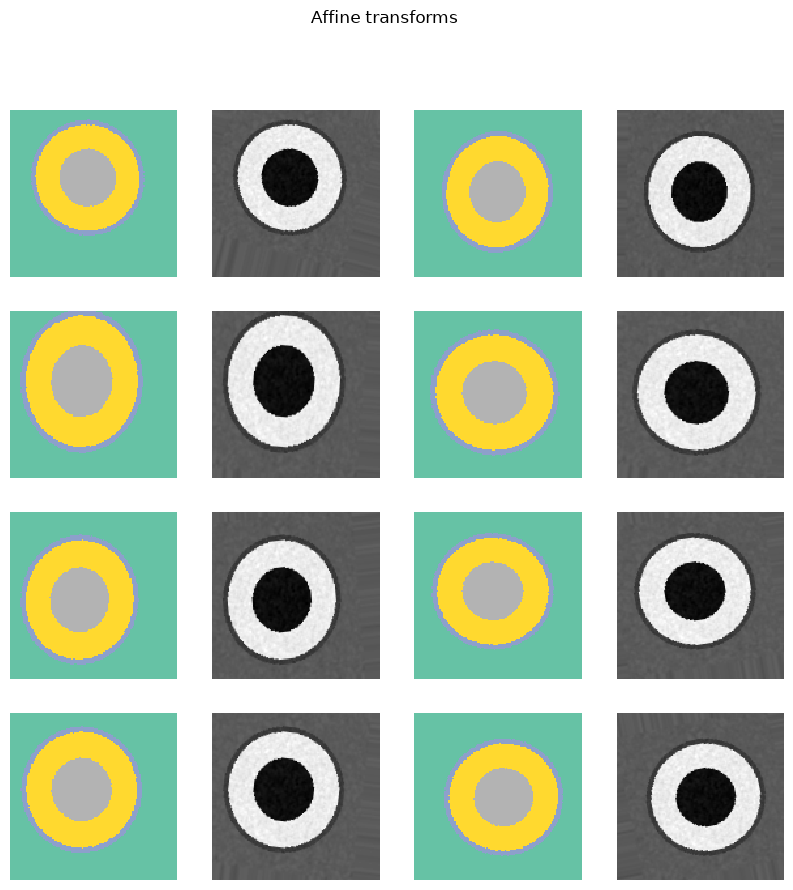

In [27]:
trf = RandomAffineTransform()
shape = [4, 4]

plt.figure(figsize=(10, 10))
for i in range(shape[0] * shape[1] // 2):
    wlab, wimg = trf(lab, img)
    plt.subplot(*shape, 2*i+1)
    plt.imshow(wlab.squeeze(), cmap='Set2', interpolation='nearest')
    plt.axis('off')
    plt.subplot(*shape, 2*i+2)
    plt.imshow(wimg.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
plt.suptitle('Affine transforms')
plt.show()

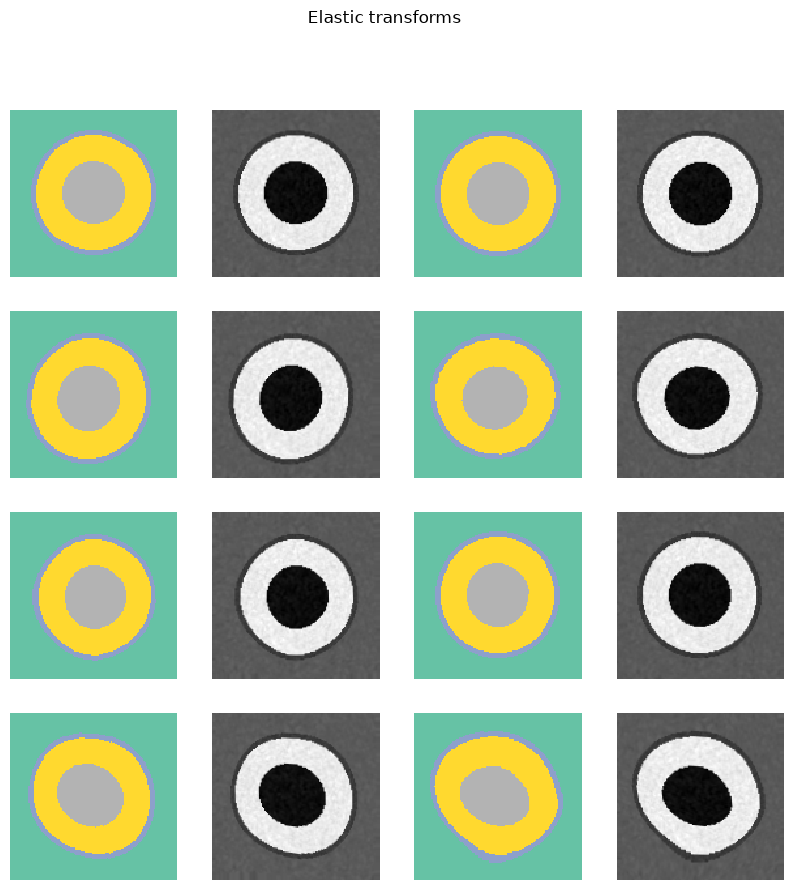

In [28]:
trf = RandomElasticTransform()
shape = [4, 4]

plt.figure(figsize=(10, 10))
for i in range(shape[0] * shape[1] // 2):
    wlab, wimg = trf(lab, img)
    plt.subplot(*shape, 2*i+1)
    plt.imshow(wlab.squeeze(), cmap='Set2', interpolation='nearest')
    plt.axis('off')
    plt.subplot(*shape, 2*i+2)
    plt.imshow(wimg.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
plt.suptitle('Elastic transforms')
plt.show()

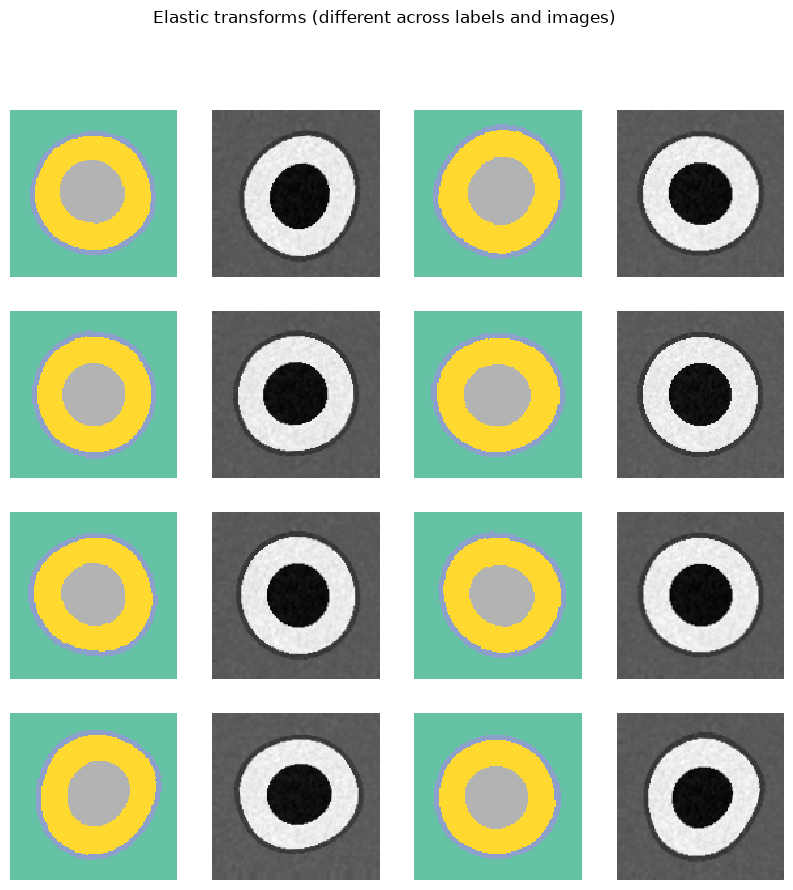

In [29]:
trf = RandomElasticTransform(shared=False)
shape = [4, 4]

plt.figure(figsize=(10, 10))
for i in range(shape[0] * shape[1] // 2):
    wlab, wimg = trf(lab, img)
    plt.subplot(*shape, 2*i+1)
    plt.imshow(wlab.squeeze(), cmap='Set2', interpolation='nearest')
    plt.axis('off')
    plt.subplot(*shape, 2*i+2)
    plt.imshow(wimg.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
plt.suptitle('Elastic transforms (different across labels and images)')
plt.show()